In [1]:
import os                                                        # Needed to create the Graphs folder
import matplotlib.pyplot as plt                                  # Plotting library

---
## <u>Results Across All Three Tasks</u>

Exact test scores copied from the three notebooks, same four models and colours in every panel. Every axis starts at zero.

Graph saved at: Images/model_comparison.png


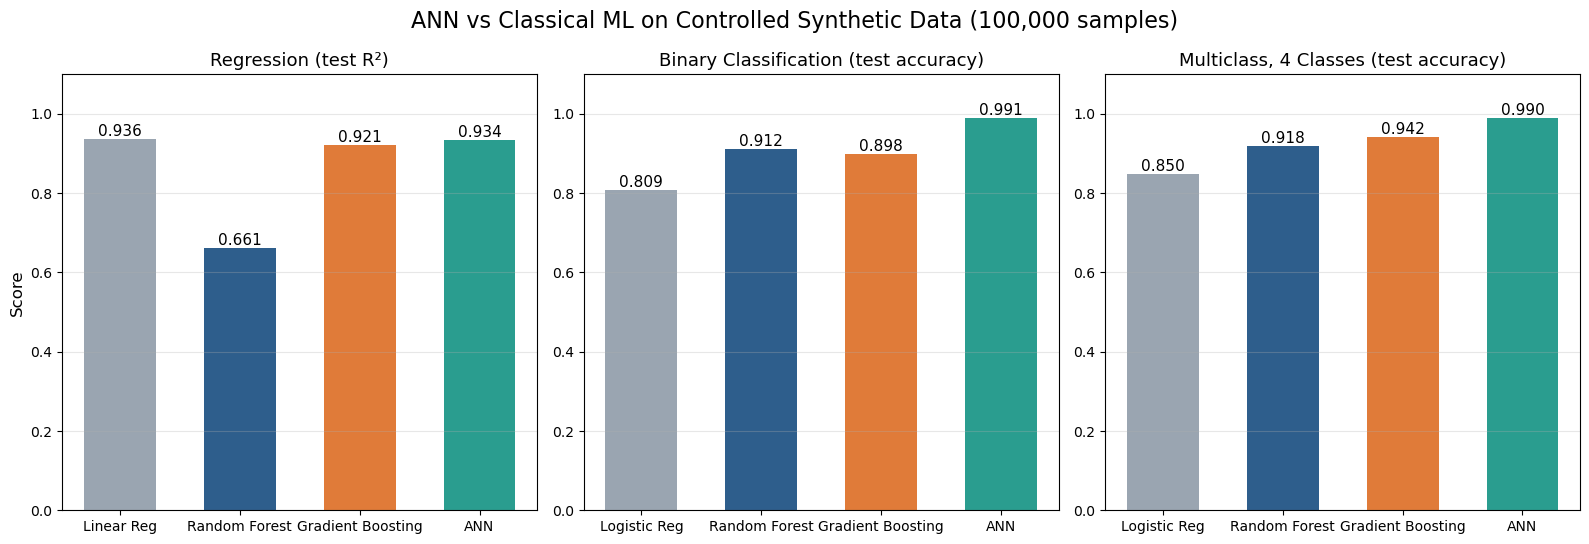

In [14]:
reg_scores = [0.9357, 0.6609, 0.9207, 0.9341]                    # Regression: test R2
bin_scores = [0.8093, 0.9117, 0.8981, 0.9910]                    # Binary classification: test accuracy
multi_scores = [0.8495, 0.9180, 0.9423, 0.9904]                  # Multiclass classification: test accuracy

all_scores = [reg_scores, bin_scores, multi_scores]              # One list of scores per panel
panel_titles = ["Regression (test R²)", "Binary Classification (test accuracy)", "Multiclass, 4 Classes (test accuracy)"]   # Title of each panel
first_names = ["Linear Reg", "Logistic Reg", "Logistic Reg"]     # First model differs between regression and classification
colors = ["#9AA5B1", "#2E5E8C", "#E07B39", "#2A9D8F"]           # Same colour for each model in every panel

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))

for i in range(3):                                               # Loops over the three tasks
    names = [first_names[i], "Random Forest", "Gradient Boosting", "ANN"]   # Model names for this panel
    bars = axes[i].bar(names, all_scores[i], color=colors, width=0.6)       # One bar per model
    axes[i].bar_label(bars, fmt="%.3f", fontsize=11)             # Exact score on top of each bar
    axes[i].set_title(panel_titles[i], fontsize=13)              # Panel title
    axes[i].set_ylim(0, 1.1)                                     # Same scale from zero in every panel, no truncated axis
    axes[i].grid(axis="y", alpha=0.3)                            # Faint horizontal grid lines
    

axes[0].set_ylabel("Score", fontsize=12)                         # y label on the first panel only
fig.suptitle("ANN vs Classical ML on Controlled Synthetic Data (100,000 samples)", fontsize=16)   # Overall title
plt.tight_layout()                                              

os.makedirs("Images", exist_ok=True)                             # Creates the folder if missing
save_path = os.path.join("Images", "model_comparison.png")       # Path of the saved image
plt.savefig(save_path, dpi=300, bbox_inches="tight")             # Saved before show so the image is not blank
print("Graph saved at:", save_path)                              # Labeled confirmation of the save location

plt.show()                                                       

---
## <u>Regression Close Up: Why Random Forest Falls Behind</u>

`make_regression` builds the target as a linear combination of the features, so Linear Regression matches the data's true structure. Random Forest uses axis aligned splits, which approximate a smooth linear relationship poorly at depth 8.

Graph saved at: Images/regression_comparison.png


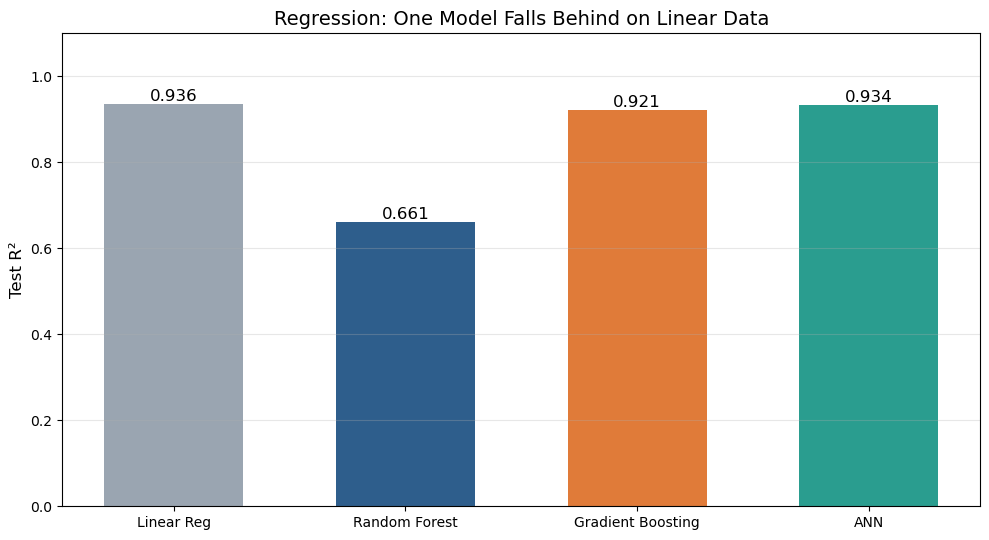

In [23]:
names = ["Linear Reg", "Random Forest", "Gradient Boosting", "ANN"]   # Models in the same order as image 1
r2_scores = [0.9357, 0.6609, 0.9207, 0.9341]                     # Exact test R2 from the regression notebook
colors = ["#9AA5B1", "#2E5E8C", "#E07B39", "#2A9D8F"]            # Same colour for each model as image 1

plt.figure(figsize=(10, 5.5))                                       

bars = plt.bar(names, r2_scores, color=colors, width=0.6)        # One bar per model
plt.bar_label(bars, fmt="%.3f", fontsize=12)                     # Exact R2 on top of each bar

plt.ylim(0, 1.1)                                                 # Axis starts at zero so the gap is not exaggerated
plt.ylabel("Test R²", fontsize=12)                               
plt.title("Regression: One Model Falls Behind on Linear Data", fontsize=14)   
plt.grid(axis="y", alpha=0.3)                                   
plt.tight_layout()                                               

save_path = os.path.join("Images", "regression_comparison.png")  
plt.savefig(save_path, dpi=300, bbox_inches="tight")             # Saved before show so the image is not blank
print("Graph saved at:", save_path)                              

plt.show()                                                       

---
## <u>Random Forest vs Gradient Boosting</u>

Random Forest leads on binary classification, but Gradient Boosting overtakes it on the 4 class problem. A model's ranking is not fixed, even between two versions of the same data generator.

The y axis is zoomed to 0.88 to 0.96 because the gaps are small (about 1 point on binary and 2 points on multiclass), so the lines look steeper than the real differences. This is also a single run with `random_state=42`, so the flip is a pattern seen in this experiment, not proof that boosting always wins on harder problems.

Graph saved at: Images/rank_flip.png


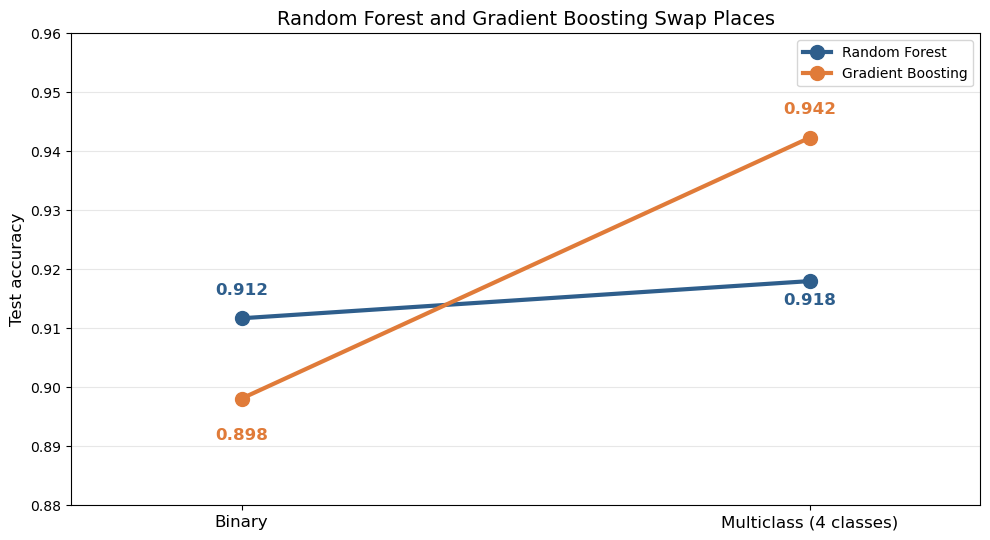

In [33]:
tasks = ["Binary", "Multiclass (4 classes)"]                    # The two tasks on the x axis
rf_acc = [0.9117, 0.9180]                                        # Random Forest test accuracy on each task
gb_acc = [0.8981, 0.9423]                                        # Gradient Boosting test accuracy on each task

plt.figure(figsize=(10, 5.5))                                       

plt.plot([0, 1], rf_acc, color="#2E5E8C", marker="o", markersize=10, linewidth=3, label="Random Forest")       # Random Forest line
plt.plot([0, 1], gb_acc, color="#E07B39", marker="o", markersize=10, linewidth=3, label="Gradient Boosting")   # Gradient Boosting line

for i in range(2):                                               # Loops over the two tasks to write the values
    plt.text(i, rf_acc[i] + 0.004 - 0.008 * i, f"{rf_acc[i]:.3f}", ha="center", color="#2E5E8C", fontsize=12, fontweight="bold")   # Random Forest value, above on the left and below on the right
    plt.text(i, gb_acc[i] - 0.007 + 0.011 * i, f"{gb_acc[i]:.3f}", ha="center", color="#E07B39", fontsize=12, fontweight="bold")   # Gradient Boosting value, below on the left and above on the right

plt.xticks([0, 1], tasks, fontsize=12)                           # Task names on the x axis
plt.xlim(-0.3, 1.3)                                              # Extra room on both sides of the points
plt.ylim(0.88, 0.96)                                             # Zoomed in on purpose, the gaps are only a few points
plt.ylabel("Test accuracy", fontsize=12)                         
plt.title("Random Forest and Gradient Boosting Swap Places", fontsize=14)   
plt.legend()                                     
plt.grid(axis="y", alpha=0.3)                                   
plt.tight_layout()                                               

save_path = os.path.join("Images", "rank_flip.png")              
plt.savefig(save_path, dpi=300, bbox_inches="tight")             
print("Graph saved at:", save_path)                              

plt.show()                                                       